In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import random
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader


SID4 = 2733
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4: {SID4}, SEED: {SEED}, SLICE: {SLICE}, HP_ID: {HP_ID}, CLS_A: {CLS_A}, CLS_B: {CLS_B}")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

SID4: 2733, SEED: 2733, SLICE: 733, HP_ID: 3, CLS_A: 3, CLS_B: 7
Device: cpu


Part 1  Data Preparation

1.1 Character-Level Tokenization

Tokenize the dataset at the character level.
Create: char_to_idx, idx_to_char
Print vocabulary size.

In [2]:
with open("shakespeare.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)

char_to_idx = {ch: i for i, ch in enumerate(chars)}
idx_to_char = {i: ch for i, ch in enumerate(chars)}

print("Vocabulary size:", vocab_size)

Vocabulary size: 49


1.2 Sliding Window Dataset

Use sequence length = 128
Create autoregressive input-target pairs:
Input: tokens [t, t+1, ..., t+127]
Target: tokens [t+1, ..., t+128]
Show 2 example input-target pairs (decoded back to text).

In [3]:
import torch
from torch.utils.data import Dataset, DataLoader

def encode(s):
    return [char_to_idx[c] for c in s]

def decode(indices):
    return "".join([idx_to_char[i] for i in indices])

class SlidingWindowDataset(Dataset):
    def __init__(self, text, seq_len=128):
        self.seq_len = seq_len
        self.data = torch.tensor(encode(text), dtype=torch.long)

    def __len__(self):
        return len(self.data) - self.seq_len

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.seq_len]
        y = self.data[idx + 1 : idx + self.seq_len + 1]
        return x, y

seq_len = 128
dataset = SlidingWindowDataset(text, seq_len=seq_len)

for i in range(2):
    x, y = dataset[i]
    print(f"--- Example Pair {i + 1} ---")
    print("Input  (x):\n", repr(decode(x.tolist())))
    print("Target (y):\n", repr(decode(y.tolist())))
    print()

--- Example Pair 1 ---
Input  (x):
 'ROMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the '
Target (y):
 'OMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the e'

--- Example Pair 2 ---
Input  (x):
 'OMEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the e'
Target (y):
 'MEO:\nBut, soft! what light through yonder window breaks?\nIt is the east, and Juliet is the sun.\nArise, fair sun, and kill the en'



Part 2 – GPT Architecture
Implement Multi-Head Masked Self-Attention
Minimum 4 heads
Proper causal masking
Manual implementation (no built-in multi-head module)Print:
Total parameter count
Hidden dimension
Number of heads
Number of layers

In [4]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model=128, n_heads=4):
        super().__init__()
        self.d_model = d_model
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.qkv_proj = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        B, T, C = x.shape

        qkv = self.qkv_proj(x)
        q, k, v = torch.chunk(qkv, 3, dim=-1)

        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(mask, float('-inf'))

        attn = F.softmax(scores, dim=-1)
        out = attn @ v

        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.out_proj(out)

In [6]:
class DecoderBlock(nn.Module):
    def __init__(self, d_model=128, n_heads=4):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model=d_model, n_heads=n_heads)
        self.ln2 = nn.LayerNorm(d_model)

        self.ff = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model)
        )

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


In [8]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, n_layers=2, seq_len=128):
        super().__init__()
        self.seq_len = seq_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(seq_len, d_model)

        self.blocks = nn.ModuleList([
            DecoderBlock(d_model=d_model, n_heads=n_heads) for _ in range(n_layers)
        ])

        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        B, T = idx.shape
        tok = self.token_emb(idx)
        pos_ids = torch.arange(T, device=idx.device)
        pos = self.pos_emb(pos_ids)

        x = tok + pos
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        logits = self.head(x)

        return logits

device = "cuda" if torch.cuda.is_available() else "cpu"

d_model = 128
n_heads = 4
n_layers = 2
seq_len = 128

model = MiniGPT(vocab_size=vocab_size, d_model=d_model, n_heads=n_heads, n_layers=n_layers, seq_len=seq_len).to(device)

total_params = sum(p.numel() for p in model.parameters())

print("Total parameter count:", total_params)
print("Hidden dimension:", d_model)
print("Number of heads:", n_heads)
print("Number of layers:", n_layers)


Total parameter count: 425777
Hidden dimension: 128
Number of heads: 4
Number of layers: 2


Part 3 – Training

Epoch 1, Loss: 1.9624
Epoch 2, Loss: 1.8966
Epoch 3, Loss: 1.8248
Epoch 4, Loss: 1.7381
Epoch 5, Loss: 1.6402
Epoch 6, Loss: 1.5281
Epoch 7, Loss: 1.4009


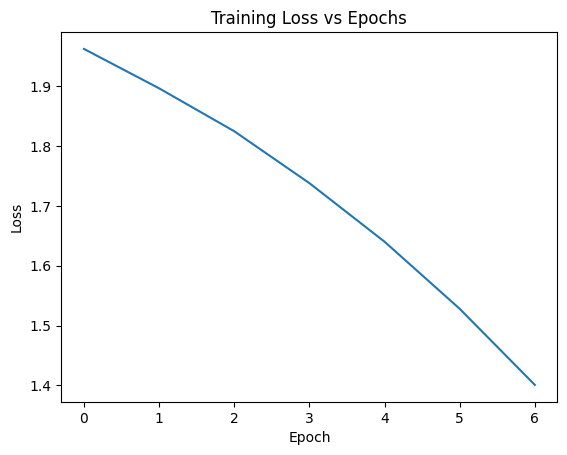

In [10]:
import matplotlib.pyplot as plt

loader = DataLoader(dataset, batch_size=32, shuffle=True)

optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss()

epochs = 7
losses = []

for ep in range(epochs):
    model.train()
    total_loss = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        loss = criterion(logits.view(-1, vocab_size), y.view(-1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg = total_loss / len(loader)
    losses.append(avg)
    print(f"Epoch {ep+1}, Loss: {avg:.4f}")

plt.plot(losses)
plt.title("Training Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

Part 4 – Sampling
Using prompt: “ROMEO:” Generate text using greedy decoding.
Implement temperature sampling.
Choose 3 temperatures showing clearly different behavior.
Implement top-k sampling.
Choose 2 values of k showing clearly different diversity.

In [11]:
@torch.no_grad()
def generate_greedy(model, prompt, max_new=150):
    model.eval()
    ids = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    for _ in range(max_new):
        ids_cond = ids[:, -model.seq_len:]
        logits = model(ids_cond)
        next_token = torch.argmax(logits[:, -1, :], dim=-1, keepdim=True)
        ids = torch.cat([ids, next_token], dim=1)
    return decode(ids[0].tolist())

@torch.no_grad()
def generate_temperature(model, prompt, max_new=150, temperature=1.0):
    model.eval()
    ids = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    for _ in range(max_new):
        ids_cond = ids[:, -model.seq_len:]
        logits = model(ids_cond)
        logits = logits[:, -1, :] / temperature
        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_token], dim=1)
    return decode(ids[0].tolist())

@torch.no_grad()
def generate_top_k(model, prompt, max_new=150, temperature=1.0, top_k=5):
    model.eval()
    ids = torch.tensor(encode(prompt), dtype=torch.long, device=device).unsqueeze(0)
    for _ in range(max_new):
        ids_cond = ids[:, -model.seq_len:]
        logits = model(ids_cond)
        logits = logits[:, -1, :] / temperature

        v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
        logits[logits < v[:, [-1]]] = float('-inf')

        probs = F.softmax(logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_token], dim=1)
    return decode(ids[0].tolist())

prompt = "ROMEO:\n"

print("1. Greedy Decoding ")
print(generate_greedy(model, prompt, max_new=150))

print("\n 2. Temperature Sampling ")
print("Low Temperature (T = 0.3):")
print(generate_temperature(model, prompt, max_new=150, temperature=0.3))

print("\nMedium Temperature (T = 1.0):")
print(generate_temperature(model, prompt, max_new=150, temperature=1.0))

print("\nHigh Temperature (T = 1.8):")
print(generate_temperature(model, prompt, max_new=150, temperature=1.8))

print("\n=== 3. Top-k Sampling ===")
print("Narrow Top-k (k = 3):")
print(generate_top_k(model, prompt, max_new=150, temperature=1.0, top_k=3))

print("\nWide Top-k (k = 20):")
print(generate_top_k(model, prompt, max_new=150, temperature=1.0, top_k=20))

1. Greedy Decoding 
ROMEO:
O Romeore, Rou thefoue the the thy wherererefair thy thy thy wherefulor s


Romeoreore Romeoreoreoreoreoreore, t Romerereomefaromerd tio,
Ro, tho, t t

 2. Temperature Sampling 
Low Temperature (T = 0.3):
ROMEO:
O Romeow Ro to thearee thethe theerd:
Beear thou t theseny thousen theny swo her s:
Tallll butin apuththid n.
Romethousesefo nd t nt nd thet winouthes

Medium Temperature (T = 1.0):
ROMEO:
O: hat I thou tat wornt theeels
Sho y I anome at’t camatl anthus this s s?
My ise, tal igue!
Thearno no wecamear haick;
RO, or fakof, at shald whe pai

High Temperature (T = 1.8):
ROMEO:
Dh:, hawis iem
We f thais nam.ulsis nous.riO twot, omme itwelf,
Ore if ha nd ntuthrno k hotnk woulhe Ronog:me;
De Ro,
Re, mal cr fou tof, e cnamerhene

=== 3. Top-k Sampling ===
Narrow Top-k (k = 3):
ROMEO:
O:
I thak tou not name? tha nou nam:
Tame thice t’s the
Thy at this nat namy thel? amy ne
Moue.
By nor, tor nononor nored nameame.
By nama palf,

O:
O

Wide Top-k (k = 20):
ROMEO